# DATASET

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

os.makedirs('data', exist_ok=True)
np.random.seed(42)
n = 250

lat_monolito  = np.random.gamma(shape=2.5, scale=35, size=n) + 40
lat_microserv = np.random.gamma(shape=2.2, scale=40, size=n) + 45

df = pd.DataFrame({
    'latencia_ms': np.concatenate([lat_monolito, lat_microserv]),
    'grupo': ['Monolito']*n + ['Microservicios']*n
})
df.to_csv('data/dataset_caso_a.csv', index=False)

# Bloque 1: Estadıstica Descriptiva y Limpieza

Dimensiones: (500, 2)

Tipos de datos:
 latencia_ms    float64
grupo           object
dtype: object

Valores ausentes:
 latencia_ms    0
grupo          0
dtype: int64

Conteo por grupo:
                 antes  despues  outliers_removidos
grupo                                             
Microservicios    250      243                   7
Monolito          250      240                  10

Estadisticos descriptivos:
                   media  mediana  desv_est  varianza  asimetria  curtosis
grupo                                                                    
Microservicios  124.614  113.969    48.204  2323.634      0.775    -0.071
Monolito        123.200  117.012    43.529  1894.787      0.620    -0.137


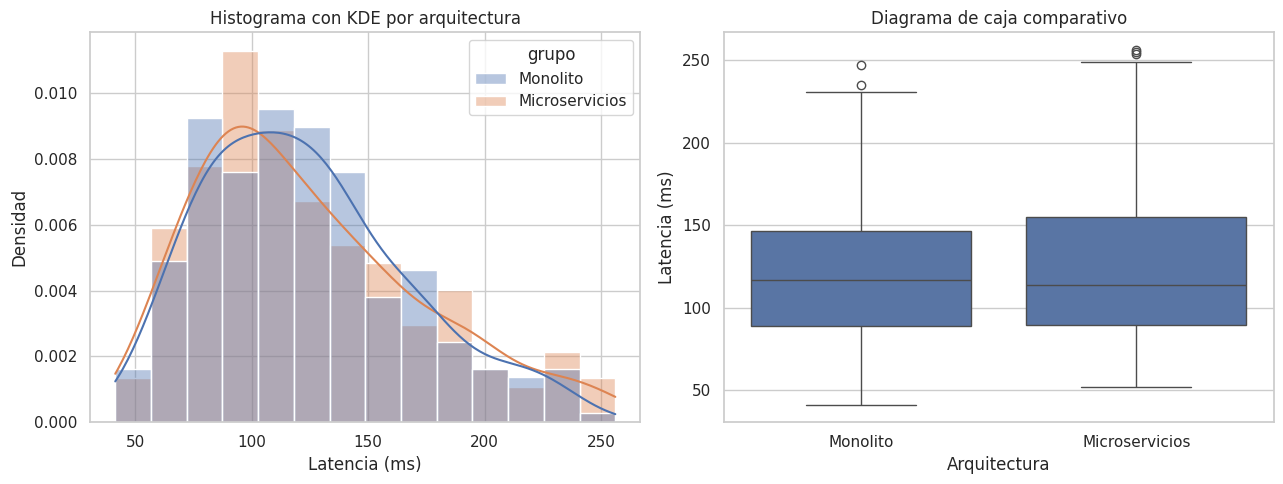

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

os.makedirs('data', exist_ok=True)
os.makedirs('docs/figuras', exist_ok=True)


df = pd.read_csv('data/dataset_caso_a.csv')
print("Dimensiones:", df.shape)
print("\nTipos de datos:\n", df.dtypes)
print("\nValores ausentes:\n", df.isna().sum())


def sin_outliers(g, col='latencia_ms'):
    q1, q3 = g[col].quantile([.25, .75])
    iqr = q3 - q1
    return g[g[col].between(q1 - 1.5*iqr, q3 + 1.5*iqr)]

df_clean = pd.concat(
    [sin_outliers(g) for _, g in df.groupby('grupo')],
    ignore_index=True
)

conteo = pd.DataFrame({
    'antes': df.groupby('grupo').size(),
    'despues': df_clean.groupby('grupo').size()
})
conteo['outliers_removidos'] = conteo['antes'] - conteo['despues']
print("\nConteo por grupo:\n", conteo)
assert (conteo['despues'] >= 200).all(), "Quedaron menos de 200 obs. en algun grupo"

df_clean.to_csv('data/dataset_caso_a_depurado.csv', index=False)

g = df_clean.groupby('grupo')['latencia_ms']
desc = pd.DataFrame({
    'media':     g.mean(),
    'mediana':   g.median(),
    'desv_est':  g.std(),
    'varianza':  g.var(),
    'asimetria': g.skew(),
    'curtosis':  g.apply(pd.Series.kurt)
})
print("\nEstadisticos descriptivos:\n", desc.round(3))


sns.set_theme(style='whitegrid')
orden = ['Monolito', 'Microservicios']

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(data=df_clean, x='latencia_ms', hue='grupo', hue_order=orden,
             kde=True, stat='density', common_norm=False, alpha=.4, ax=ax[0])
ax[0].set_title('Histograma con KDE por arquitectura')
ax[0].set_xlabel('Latencia (ms)')
ax[0].set_ylabel('Densidad')

sns.boxplot(data=df_clean, x='grupo', y='latencia_ms', order=orden, ax=ax[1])
ax[1].set_title('Diagrama de caja comparativo')
ax[1].set_xlabel('Arquitectura')
ax[1].set_ylabel('Latencia (ms)')

plt.tight_layout()
plt.savefig('docs/figuras/bloque1_hist_box.png', dpi=150)
plt.show()

# Bloque 2: Distribuciones de Muestreo y Teorema Central del Lımite

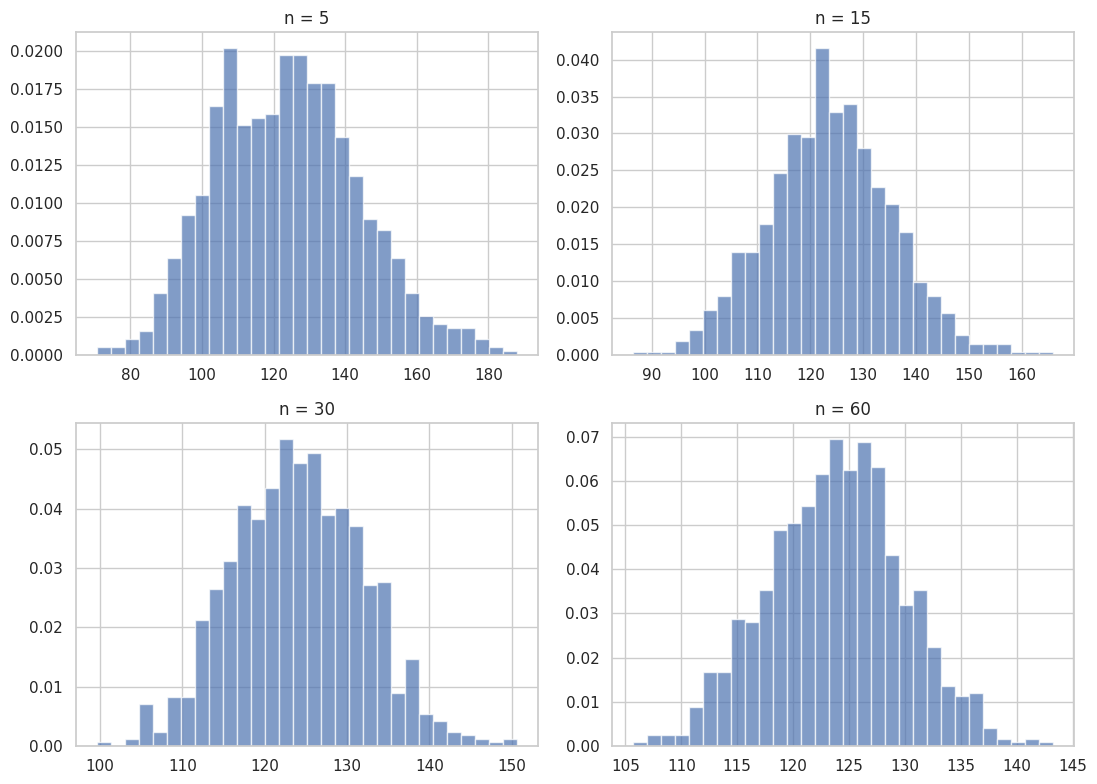

    n  EE_empirico  EE_teorico
0   5       19.925      20.526
1  15       11.597      11.851
2  30        7.880       8.380
3  60        5.999       5.925


In [ ]:
datos = df_clean['latencia_ms'].values   # muestra global
s = datos.std(ddof=1)
rng = np.random.default_rng(42)

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
resultados = []
for ax, m in zip(axes.ravel(), [5, 15, 30, 60]):
    medias = np.array([rng.choice(datos, size=m, replace=True).mean() for _ in range(1000)])
    ax.hist(medias, bins=30, density=True, alpha=.7)
    ax.set_title(f'n = {m}')
    resultados.append({'n': m,
                       'EE_empirico': medias.std(ddof=1),
                       'EE_teorico': s/np.sqrt(m)})
plt.tight_layout(); plt.show()
print(pd.DataFrame(resultados).round(3))

# Bloque 3: Estimacion por Intervalos de Confianza

In [ ]:
xbar, se, N = datos.mean(), stats.sem(datos), len(datos)
for conf in [0.90, 0.95, 0.99]:
    li, ls = stats.t.interval(conf, df=N-1, loc=xbar, scale=se)
    print(f'{conf:.0%}: ({li:.2f}, {ls:.2f})')


a = df_clean.loc[df_clean.grupo=='Microservicios', 'latencia_ms']
b = df_clean.loc[df_clean.grupo=='Monolito', 'latencia_ms']

lev = stats.levene(a, b)
iguales = lev.pvalue > 0.05
print(lev, '-> varianzas iguales' if iguales else '-> usar Welch')

diff = a.mean() - b.mean()
va, vb, na, nb = a.var(ddof=1), b.var(ddof=1), len(a), len(b)
if iguales:
    sp2 = ((na-1)*va + (nb-1)*vb)/(na+nb-2)
    se_d = np.sqrt(sp2*(1/na + 1/nb)); gl = na+nb-2
else:
    se_d = np.sqrt(va/na + vb/nb)
    gl = (va/na + vb/nb)**2 / ((va/na)**2/(na-1) + (vb/nb)**2/(nb-1))
tc = stats.t.ppf(0.975, gl)
ic = (diff - tc*se_d, diff + tc*se_d)
print(f'Diferencia = {diff:.2f}, IC95% = ({ic[0]:.2f}, {ic[1]:.2f})')
print('¿0 en el IC?', ic[0] <= 0 <= ic[1])

90%: (120.47, 127.35)
95%: (119.81, 128.02)
99%: (118.51, 129.31)
LeveneResult(statistic=np.float64(1.8419292738748558), pvalue=np.float64(0.17536147587024106)) -> varianzas iguales
Diferencia = 1.41, IC95% = (-6.80, 9.63)
¿0 en el IC? True


# Bloque 4: Teorıa de Decision en Estadıstica

Hipótesis:  
H₀: μ_micro ≤ μ_mono (los microservicios no aumentan la latencia)  
H₁: μ_micro > μ_mono (los microservicios sí aumentan la latencia)  
α = 0.05


### Matriz de decisión

| Decisión | H0 verdadera (microservicios NO aumentan la latencia) | H0 falsa (microservicios SÍ aumentan la latencia) |
|:---|:---|:---|
| **Rechazar H0** | Error Tipo I (α = 0.05) | Decisión correcta (potencia = 1 − β) |
| **No rechazar H0** | Decisión correcta (confianza = 1 − α) | Error Tipo II (β) |

**Costo del Error Tipo I (α):** se concluye que los microservicios son más lentos cuando en realidad no lo son. Se invierte tiempo y dinero en optimizar o rediseñar la arquitectura sin necesidad, o se descarta una migración que sí convenía.

**Costo del Error Tipo II (β):** se ignora una latencia real. Se despliega en producción una arquitectura más lenta, lo que degrada la experiencia del usuario, puede incumplir los SLA y obliga a rehacer trabajo después.

In [ ]:
alpha = 0.05
t_stat, p_val = stats.ttest_ind(a, b, equal_var=iguales, alternative='greater')
print(f't = {t_stat:.3f}, p-value = {p_val:.4g}')
print('Rechazar H0' if p_val < alpha else 'No rechazar H0')

t = 0.338, p-value = 0.3676
No rechazar H0
